# Tabular Branch — Q-CHAT-10, XGBoost and Data-Leakage Audit

**Thesis:** Early detection of autism spectrum disorder in children aged 8 years or younger using machine learning on questionnaires and facial images.

**Methodology:** CRISP-ML(Q) (2021) — this notebook covers the *Data Understanding*, *Data Preparation*, *Modeling* and *Evaluation* phases, with emphasis on the **quality assurance** phase that CRISP-ML(Q) adds and CRISP-DM does not include.

---

## Methodological warning

The audit in Section 3 shows that, in this dataset, the `ASD_traits` label **is not a clinical diagnosis**: it is the deterministic result of applying the Q-CHAT-10 score threshold to the same answers that are used as predictors.

This notebook therefore **does not train an ASD detector**. It trains and audits a model that reproduces a known arithmetic rule, and it formally quantifies that limitation. That quantification is the methodological contribution of this branch.

## Objectives

1. **Audit the integrity** of the `data_asd.csv` file and document the cleaning.
2. **Formally demonstrate the information leakage** between the items and the label.
3. **Apply the pediatric inclusion criterion** (`Age_Years <= 8`).
4. **EDA** of the cleaned cohort.
5. **Three models compared** with stratified 10-fold cross-validation:
   - Arithmetic baseline `sum(A1..A10) > k`, with no machine learning.
   - **Experiment A:** XGBoost on the 10 Q-CHAT-10 items.
   - **Experiment B:** XGBoost on the clinical and demographic variables, **excluding** the items.
6. **Honest evaluation:** threshold calibrated on train, blind hold-out, McNemar test, calibration, prevalence-adjusted PPV and subgroup fairness.
7. **Explainability** with TreeSHAP.
8. **Export** for late fusion with the image branch.

> **Repository `asd-screening-audit` · Notebook 1 of 5 — Questionnaire branch (Q-CHAT-10)**
>
> Academic research on early ASD screening with public data. **This is not a diagnostic tool** and its results must not be used for clinical decisions.

| | |
|---|---|
| **Run order** | Notebooks 01 → 02 → 03 → 04 → 05. Notebook 05 requires the outputs of 01, 03 and 04 (optional); 01 and 02 are independent of each other. |
| **Inputs** | `data/cuestionario/data_asd.csv` |
| **Outputs** | In `outputs/rama_tabular/`: `tabular_holdout_scores.csv`, `tabular_oof_scores.csv`, `metadatos_ejecucion.json`, `tabla1_comparacion_modelos.csv`, `tabla2_caracteristicas_rama.csv`, `tabla3_sensibilidad_edad.csv`, `rama_regla_salida_fusion.csv`. Model in `models/rama_tabular/`. |
| **Hardware** | CPU (a few minutes) |
| **Data** | Source, license and folder layout: see `data/README.md` in the repository. |
| **Reproducibility** | Global seed `SEED = 42`. The first code cell defines `PROJECT_DIR`; there are no other hard-coded paths. |

*File and folder names (`rama_tabular`, `tabla1_...`) are kept in Spanish so that they match the original runs and the article.*


---
## 1. Environment Setup

We fix the global seed and the project paths. Exact reproducibility is a CRISP-ML(Q) requirement: any third party must be able to regenerate every number in this notebook.

In [3]:
# ==============================================================================
# CELL 1: Dependencies and imports
# ==============================================================================
!pip install -q xgboost shap statsmodels

import os, warnings, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import shap, joblib
from scipy import stats

from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.calibration import calibration_curve
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix,
                             classification_report, roc_curve, brier_score_loss)
import xgboost as xgb

warnings.filterwarnings('ignore')
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'

SEED = 42
np.random.seed(SEED)

print("Entorno configurado | xgboost", xgb.__version__)

Entorno configurado | xgboost 3.4.1


In [4]:
# ==============================================================================
# CELL 2: Project paths and dataset loading
# ==============================================================================
# Project paths. Only adjust PROJECT_DIR
# (outside Colab, set the environment variable ASD_PROJECT_DIR).
try:
    from google.colab import drive
    drive.mount('/content/drive')
    PROJECT_DIR = "/content/drive/MyDrive/asd-screening-audit"
except ImportError:
    PROJECT_DIR = os.environ.get("ASD_PROJECT_DIR", ".")

DATA_DIR    = os.path.join(PROJECT_DIR, "data", "cuestionario")
MODELS_DIR  = os.path.join(PROJECT_DIR, "models", "rama_tabular")
OUTPUTS_DIR = os.path.join(PROJECT_DIR, "outputs", "rama_tabular")
for d in [MODELS_DIR, OUTPUTS_DIR]:
    os.makedirs(d, exist_ok=True)

CSV_PATH = os.path.join(DATA_DIR, "data_asd.csv")
if not os.path.exists(CSV_PATH):
    CSV_PATH = "data_asd.csv"          # alternative: file in the working folder

df_raw = pd.read_csv(CSV_PATH)
print(f"Dataset loaded: {CSV_PATH}")
print(f"Dimensiones crudas: {df_raw.shape[0]} rows x {df_raw.shape[1]} columnas")
display(df_raw.head())

Mounted at /content/drive
Dataset loaded: /content/drive/MyDrive/asd-screening-audit/data/cuestionario/data_asd.csv
Dimensiones crudas: 1985 rows x 28 columnas


,CASE_NO_PATIENT'S,A1,A2,A3,A4,A5,A6,A7,A8,A9,...,Global developmental delay/intellectual disability,Social/Behavioural Issues,Childhood Autism Rating Scale,Anxiety_disorder,Sex,Ethnicity,Jaundice,Family_mem_with_ASD,Who_completed_the_test,ASD_traits
0,1,0,0,0,0,0,0,1,1,0,...,Yes,Yes,1,Yes,F,middle eastern,Yes,No,Family Member,No
1,2,1,1,0,0,0,1,1,0,0,...,Yes,Yes,2,Yes,M,White European,Yes,No,Family Member,Yes
2,3,1,0,0,0,0,0,1,1,0,...,Yes,Yes,4,Yes,M,Middle Eastern,Yes,No,Family Member,Yes
3,4,1,1,1,1,1,1,1,1,1,...,Yes,Yes,2,Yes,M,Hispanic,No,No,Family Member,Yes
4,5,1,1,0,1,1,1,1,1,1,...,Yes,Yes,1,Yes,F,White European,No,No,Family Member,Yes


### Environment versions

In [ ]:
# Environment versions (for the Methods section and requirements.txt)
import sys, platform, importlib.metadata as md
print("Python", sys.version.split()[0], "|", platform.platform())
for p in ["numpy", "pandas", "scipy", "scikit-learn", "xgboost", "tensorflow", "keras",
          "opencv-python", "imagehash", "shap", "statsmodels", "matplotlib", "seaborn",
          "joblib", "Pillow"]:
    try: print(f"{p:<16}{md.version(p)}")
    except Exception: print(f"{p:<16}(not installed)")
try:
    import tensorflow as tf; print("GPU:", [d.name for d in tf.config.list_physical_devices('GPU')])
except Exception: pass


---
## 2. Naming Standardization

We normalize column names to `snake_case` and homogenize the text of the categorical variables. This step is not cosmetic: the dataset contains the same category written in different ways (`'White European'` and `'white european'`, `'Family Member'` and `'Family member'`), which, left unnormalized, would produce duplicated *one-hot* columns and dilute the signal.

In [5]:
# ==============================================================================
# CELL 3: Name and category normalization
# ==============================================================================
df = df_raw.copy()
df.columns = (df.columns.str.strip().str.replace("'", "", regex=False)
                        .str.replace(" ", "_", regex=False)
                        .str.replace("/", "_", regex=False).str.lower())

for c in df.columns:
    if not pd.api.types.is_numeric_dtype(df[c]):
        df[c] = df[c].astype(str).str.strip().str.lower().replace('nan', np.nan)

Q_ITEMS = ['a1','a2','a3','a4','a5','a6','a7','a8','a9','a10_autism_spectrum_quotient']
df[Q_ITEMS] = df[Q_ITEMS].apply(pd.to_numeric, errors='coerce')
for c in ['age_years','qchat_10_score','social_responsiveness_scale',
          'childhood_autism_rating_scale']:
    df[c] = pd.to_numeric(df[c], errors='coerce')

df['suma_qchat'] = df[Q_ITEMS].sum(axis=1)
df['target']     = (df['asd_traits'] == 'yes').astype(int)

print("Normalized columns:")
print(df.columns.tolist())
print(f"\nUnique categories in 'ethnicity' after normalizing: {df['ethnicity'].nunique()}")

Normalized columns:
['case_no_patients', 'a1', 'a2', 'a3', 'a4', 'a5', 'a6', 'a7', 'a8', 'a9', 'a10_autism_spectrum_quotient', 'social_responsiveness_scale', 'age_years', 'qchat_10_score', 'speech_delay_language_disorder', 'learning_disorder', 'genetic_disorders', 'depression', 'global_developmental_delay_intellectual_disability', 'social_behavioural_issues', 'childhood_autism_rating_scale', 'anxiety_disorder', 'sex', 'ethnicity', 'jaundice', 'family_mem_with_asd', 'who_completed_the_test', 'asd_traits', 'suma_qchat', 'target']

Unique categories in 'ethnicity' after normalizing: 11


---
## 3. Dataset Integrity Audit

This section corresponds to the **Data Validation** phase of CRISP-ML(Q). Before modeling, we verify that the file is a homogeneous body of data and not a concatenation of heterogeneous sources.

We apply four tests:

1. **Internal consistency:** does the sum of the items match the `qchat_10_score` column?
2. **Label-score coherence:** does the label follow a stable rule with respect to the score?
3. **Duplication:** how many records are exact copies of another one?
4. **Degeneration of clinical variables:** has any clinical scale lost its variance?

The analysis in blocks of 100 rows reveals an abrupt discontinuity that none of the isolated tests would make evident.

=== PROFILE BY BLOCKS OF 100 ROWS ===
 fila_inicio   n  coherencia  suma_media  pct_items_cero  cars_unicos  srs_max
           0 100        1.00    3.890000        0.170000            4      8.0
         100 100        1.00    4.430000        0.030000            4     10.0
         200 100        1.00    5.810000        0.040000            4     10.0
         300 100        1.00    5.370000        0.070000            4     10.0
         400 100        1.00    5.500000        0.040000            4     10.0
         500 100        1.00    5.590000        0.000000            4     10.0
         600 100        1.00    5.900000        0.020000            3     10.0
         700 100        1.00    5.450000        0.030000            4     10.0
         800 100        1.00    5.340000        0.090000            3     10.0
         900 100        1.00    5.100000        0.030000            4     10.0
        1000 100        0.82    2.650000        0.390000            4     10.0
        1100 1

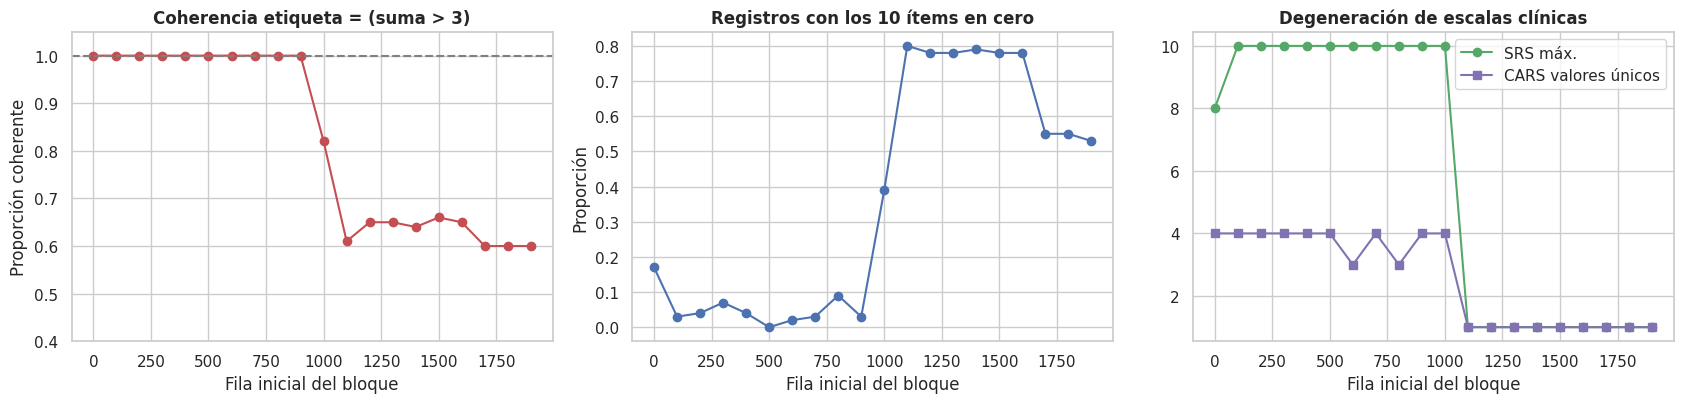

In [6]:
# ==============================================================================
# CELL 4: Block-wise audit — detection of structural discontinuity
# ==============================================================================
df['coherente'] = ((df['suma_qchat'] > 3).astype(int) == df['target'])

bloques = []
for i in range(0, len(df), 100):
    b = df.iloc[i:i+100]
    bloques.append({
        'fila_inicio'   : i,
        'n'             : len(b),
        'coherencia'    : b['coherente'].mean(),
        'suma_media'    : b['suma_qchat'].mean(),
        'pct_items_cero': (b['suma_qchat'] == 0).mean(),
        'cars_unicos'   : b['childhood_autism_rating_scale'].nunique(),
        'srs_max'       : b['social_responsiveness_scale'].max(),
    })
df_bloques = pd.DataFrame(bloques)
print("=== PROFILE BY BLOCKS OF 100 ROWS ===")
print(df_bloques.to_string(index=False))

fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
axes[0].plot(df_bloques.fila_inicio, df_bloques.coherencia, 'o-', color='#C44E52')
axes[0].axhline(1.0, ls='--', c='gray'); axes[0].set_ylim(0.4, 1.05)
axes[0].set_title("Label coherence = (sum > 3)", fontweight='bold')
axes[0].set_xlabel("Block start row"); axes[0].set_ylabel("Coherent proportion")

axes[1].plot(df_bloques.fila_inicio, df_bloques.pct_items_cero, 'o-', color='#4C72B0')
axes[1].set_title("Records with all 10 items at zero", fontweight='bold')
axes[1].set_xlabel("Block start row"); axes[1].set_ylabel("Proportion")

axes[2].plot(df_bloques.fila_inicio, df_bloques.srs_max, 'o-', color='#55A868',
             label='SRS max.')
axes[2].plot(df_bloques.fila_inicio, df_bloques.cars_unicos, 's-', color='#8172B2',
             label='CARS unique values')
axes[2].set_title("Degeneration of clinical scales", fontweight='bold')
axes[2].set_xlabel("Block start row"); axes[2].legend()

plt.tight_layout()
plt.savefig(os.path.join(OUTPUTS_DIR, "auditoria_bloques.png"), dpi=300)
plt.show()

In [7]:
# ==============================================================================
# CELL 5: Quantification of the anomalies
# ==============================================================================
print("=" * 74)
print(" TEST 1 — Internal consistency: sum(A1..A10) vs qchat_10_score")
print("=" * 74)
print(f"  Coincidencia exacta: {(df['suma_qchat'] == df['qchat_10_score']).mean():.4f}")

print("\n" + "=" * 74)
print(" TEST 2 — Label-score coherence (contingency table)")
print("=" * 74)
print(pd.crosstab(df['suma_qchat'], df['asd_traits']))
print("\n  Accuracy of the 'sum > k' rule on the whole file:")
for k in range(11):
    print(f"    sum > {k:>2} : {((df.suma_qchat > k).astype(int) == df.target).mean():.4f}")

print("\n" + "=" * 74)
print(" TEST 3 — Exact duplication")
print("=" * 74)
dups = df.drop(columns=['case_no_patients']).duplicated(keep='first')
print(f"  Duplicated rows: {dups.sum()} de {len(df)} ({dups.mean()*100:.1f}%)")
vc = df.drop(columns=['case_no_patients']).value_counts()
print(f"  Maximum multiplicity of a single record: {vc.iloc[0]} repeticiones")

print("\n" + "=" * 74)
print(" TEST 4 — Degeneration of clinical scales")
print("=" * 74)
sospechoso = ((df['social_responsiveness_scale'] <= 1) &
              (df['childhood_autism_rating_scale'] == 1))
print(f"  Records with SRS<=1 AND CARS==1 simultaneously: {sospechoso.sum()}")
print("  (SRS 0-10 and CARS 1-4 are independent scales: their joint collapse")
print("   at the minimum value has no possible clinical interpretation)")
print(f"\n  Coherence in that subset      : {df.loc[sospechoso, 'coherente'].mean():.4f}")
print(f"  Coherence in the rest          : {df.loc[~sospechoso, 'coherente'].mean():.4f}")

 TEST 1 — Internal consistency: sum(A1..A10) vs qchat_10_score
  Coincidencia exacta: 0.5884

 TEST 2 — Label-score coherence (contingency table)
asd_traits   no  yes
suma_qchat          
0           422  295
1           305   51
2            88    0
3            96    0
4             0  110
5             0  120
6             0   96
7             0  135
8             0   97
9             0   95
10            0   75

  Accuracy of the 'sum > k' rule on the whole file:
    sum >  0 : 0.6050
    sum >  1 : 0.7330
    sum >  2 : 0.7773
    sum >  3 : 0.8257
    sum >  4 : 0.7703
    sum >  5 : 0.7098
    sum >  6 : 0.6615
    sum >  7 : 0.5935
    sum >  8 : 0.5446
    sum >  9 : 0.4967
    sum > 10 : 0.4589

 TEST 3 — Exact duplication
  Duplicated rows: 656 de 1985 (33.0%)
  Maximum multiplicity of a single record: 37 repeticiones

 TEST 4 — Degeneration of clinical scales
  Records with SRS<=1 AND CARS==1 simultaneously: 955
  (SRS 0-10 and CARS 1-4 are independent scales: their joint c

### 3.1 Audit conclusion and cleaning criterion

The four tests converge on the same breakpoint: **the file concatenates two different sources**.

- **Primary source (≈1054 records):** internally consistent, clinical scales with variance, 100% label-score coherence.
- **Appended source (≈931 records):** 71% of records with all ten answers equal to zero, 651 exact duplicates, `CARS` constant at 1 and `SRS` collapsed to {0,1}, and labels unrelated to the answers.

We define an **objective and reproducible exclusion criterion** that does not depend on the row position in the file:

> A record is excluded if it meets **any** of these conditions:
> 1. The label contradicts the instrument's scoring rule (`target ≠ sum > 3`).
> 2. It is an exact duplicate of a previous record.
> 3. It shows joint degeneration of clinical scales (`SRS ≤ 1` **and** `CARS == 1`).

The criterion is deliberately conservative: it removes 100% of the appended source at the cost of discarding ~29 legitimate records of the primary source (2.8%). We prefer to lose valid data rather than contaminate the cohort.

In [8]:
# ==============================================================================
# CELL 6: Applying the cleaning criterion and the pediatric filter
# ==============================================================================
n0 = len(df)
crit_incoherente = ~df['coherente']
crit_duplicado   = df.drop(columns=['case_no_patients']).duplicated(keep='first')
crit_degenerado  = sospechoso

excluir = crit_incoherente | crit_duplicado | crit_degenerado
df_val = df[~excluir].copy()

print("=" * 74)
print(" CLEANING TRACE (for the Methods section)")
print("=" * 74)
print(f"  Raw records                               : {n0}")
print(f"  (-) Incoherent with the Q-CHAT rule       : {crit_incoherente.sum()}")
print(f"  (-) Duplicados exactos                    : {crit_duplicado.sum()}")
print(f"  (-) Degenerate clinical scales            : {crit_degenerado.sum()}")
print(f"  (overlap between criteria)                : "
      f"{crit_incoherente.sum()+crit_duplicado.sum()+crit_degenerado.sum()-excluir.sum()}")
print(f"  = Valid records                           : {len(df_val)}")

# --- Pediatric inclusion criterion ---
EDAD_MAX = 8
df_ped = df_val[df_val['age_years'] <= EDAD_MAX].copy()
print(f"\n  (-) Older than {EDAD_MAX} years                     : {len(df_val)-len(df_ped)}")
print(f"  = FINAL PEDIATRIC COHORT                  : {len(df_ped)}")
print("=" * 74)
print(f"\n  TEA (yes) : {df_ped.target.sum()}  ({df_ped.target.mean()*100:.1f}%)")
print(f"  Control   : {(1-df_ped.target).sum()}  ({(1-df_ped.target).mean()*100:.1f}%)")

# Columns that lost all variance after cleaning: they add nothing and must go
CONSTANTES = [c for c in df_ped.columns if df_ped[c].nunique(dropna=False) <= 1]
print(f"\n  Constant columns in the cleaned cohort ({len(CONSTANTES)}):")
for c in CONSTANTES:
    print(f"    - {c}  (single value: {df_ped[c].dropna().unique()[:1]})")

 CLEANING TRACE (for the Methods section)
  Raw records                               : 1985
  (-) Incoherent with the Q-CHAT rule       : 346
  (-) Duplicados exactos                    : 656
  (-) Degenerate clinical scales            : 955
  (overlap between criteria)                : 997
  = Valid records                           : 1025

  (-) Older than 8 years                     : 475
  = FINAL PEDIATRIC COHORT                  : 550

  TEA (yes) : 371  (67.5%)
  Control   : 179  (32.5%)

  Constant columns in the cleaned cohort (5):
    - speech_delay_language_disorder  (single value: ['yes'])
    - learning_disorder  (single value: ['yes'])
    - depression  (single value: ['yes'])
    - global_developmental_delay_intellectual_disability  (single value: ['yes'])
    - coherente  (single value: [ True])


In [9]:
# ==============================================================================
# CELL 6b: Cleaning without the label criterion
# Runs AFTER CELL 6 (uses df, crit_incoherente, crit_duplicado,
# crit_degenerado, excluir and df_ped defined there).
# ==============================================================================
import itertools
excl_indep = crit_duplicado | crit_degenerado            # criteria that do NOT use the label
print("=" * 74)
print(" CIRCULARITY CHECK OF THE CRITERION 'label different from (sum > 3)'")
print("=" * 74)
print(f" Exclusions with the three criteria             : {int(excluir.sum())}")
print(f" Exclusions with duplicates + degenerate only   : {int(excl_indep.sum())}")
print(f" Same records excluded?                         : {bool((excluir == excl_indep).all())}")
print(f" Records excluded only because of the label     : {int((crit_incoherente & ~excl_indep).sum())}")
print(f" Label-rule coherence in the cohort without using the label: "
      f"{df.loc[~excl_indep, 'coherente'].mean():.4f} (n = {int((~excl_indep).sum())})")
print("\n Overlap of criteria (label, duplicate, degenerate) -> n:")
for c in itertools.product([False, True], repeat=3):
    m = (crit_incoherente == c[0]) & (crit_duplicado == c[1]) & (crit_degenerado == c[2])
    print(f"   {str(c):<24} {int(m.sum())}")
print(f"\n Pediatric cohort obtained without the label: "
      f"{int((~excl_indep & (df.age_years <= EDAD_MAX)).sum())} | cohort used: {len(df_ped)}")

 CIRCULARITY CHECK OF THE CRITERION 'label different from (sum > 3)'
 Exclusions with the three criteria             : 960
 Exclusions with duplicates + degenerate only   : 960
 Same records excluded?                         : True
 Records excluded only because of the label     : 0
 Label-rule coherence in the cohort without using the label: 1.0000 (n = 1025)

 Overlap of criteria (label, duplicate, degenerate) -> n:
   (False, False, False)    1025
   (False, False, True)     183
   (False, True, False)     5
   (False, True, True)      426
   (True, False, False)     0
   (True, False, True)      121
   (True, True, False)      0
   (True, True, True)       225

 Pediatric cohort obtained without the label: 550 | cohort used: 550


---
## 4. Exploratory Analysis of the Cleaned Cohort

With the validated cohort, we characterize the class distribution, the age structure and the individual relationship of each item with the label.

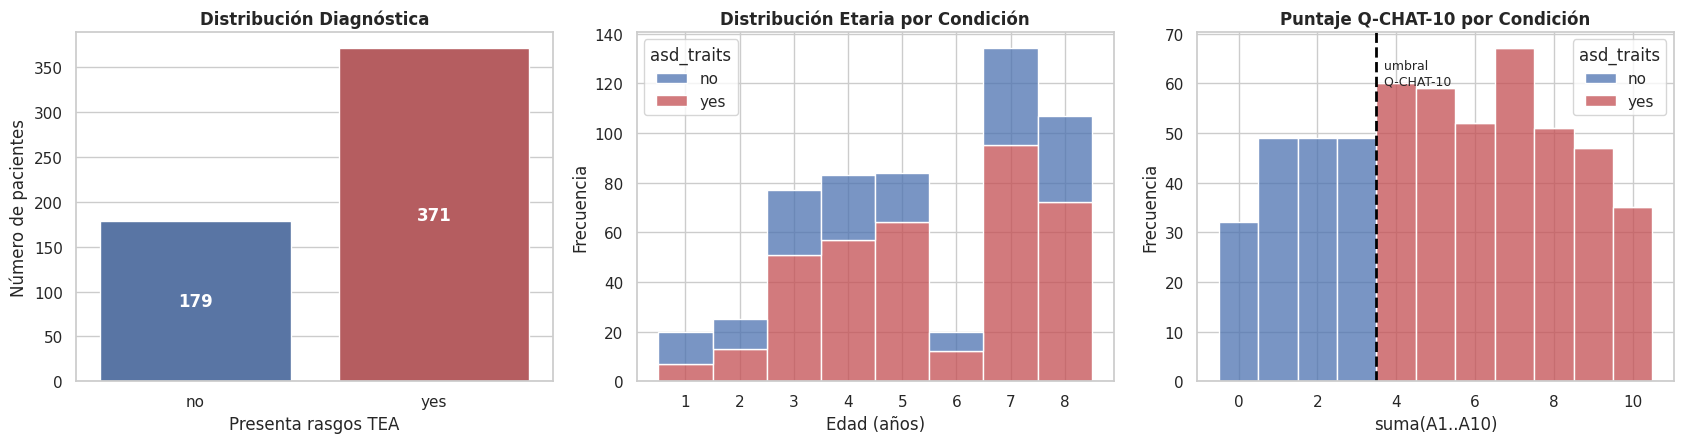

NOTE on the third panel: the separation is perfect with no overlap.
No real clinical variable produces such a boundary. It is the visual signature
of the label being derived from the score itself (see Section 5).


In [10]:
# ==============================================================================
# CELL 7: Class, age and score distributions
# ==============================================================================
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))

sns.countplot(data=df_ped, x='asd_traits', ax=axes[0], palette=['#4C72B0', '#C44E52'])
axes[0].set_title("Diagnostic Distribution", fontweight='bold')
axes[0].set_xlabel("Shows ASD traits"); axes[0].set_ylabel("Number of patients")
for p in axes[0].patches:
    axes[0].annotate(f'{int(p.get_height())}',
                     (p.get_x()+p.get_width()/2., p.get_height()/2),
                     ha='center', va='center', color='white', fontweight='bold')

sns.histplot(data=df_ped, x='age_years', hue='asd_traits', multiple='stack',
             discrete=True, ax=axes[1], palette=['#4C72B0', '#C44E52'])
axes[1].set_title("Age Distribution by Condition", fontweight='bold')
axes[1].set_xlabel("Age (years)"); axes[1].set_ylabel("Frecuencia")

sns.histplot(data=df_ped, x='suma_qchat', hue='asd_traits', multiple='stack',
             discrete=True, ax=axes[2], palette=['#4C72B0', '#C44E52'])
axes[2].axvline(3.5, color='black', ls='--', lw=2)
axes[2].text(3.6, axes[2].get_ylim()[1]*0.85, ' threshold\n Q-CHAT-10', fontsize=9)
axes[2].set_title("Q-CHAT-10 Score by Condition", fontweight='bold')
axes[2].set_xlabel("sum(A1..A10)"); axes[2].set_ylabel("Frecuencia")

plt.tight_layout()
plt.savefig(os.path.join(OUTPUTS_DIR, "eda_cohorte_depurada.png"), dpi=300)
plt.show()

print("NOTE on the third panel: the separation is perfect with no overlap.")
print("No real clinical variable produces such a boundary. It is the visual signature")
print("of the label being derived from the score itself (see Section 5).")

=== Association of each item with the label (Holm, 10 comparisons) ===
                        Item      phi      p_bruto       p_holm  signif
                          a7 0.578516 6.249090e-42 6.249090e-41    True
                          a9 0.573390 3.197713e-41 2.877942e-40    True
                          a6 0.568803 1.361612e-40 1.089289e-39    True
                          a5 0.557250 4.973375e-39 3.481363e-38    True
                          a4 0.518502 5.078436e-34 3.047061e-33    True
                          a1 0.513655 2.028841e-33 1.014421e-32    True
                          a3 0.451792 3.127786e-26 1.251114e-25    True
                          a2 0.439865 5.981902e-25 1.794571e-24    True
                          a8 0.409932 6.994085e-22 1.398817e-21    True
a10_autism_spectrum_quotient 0.203004 1.927691e-06 1.927691e-06    True


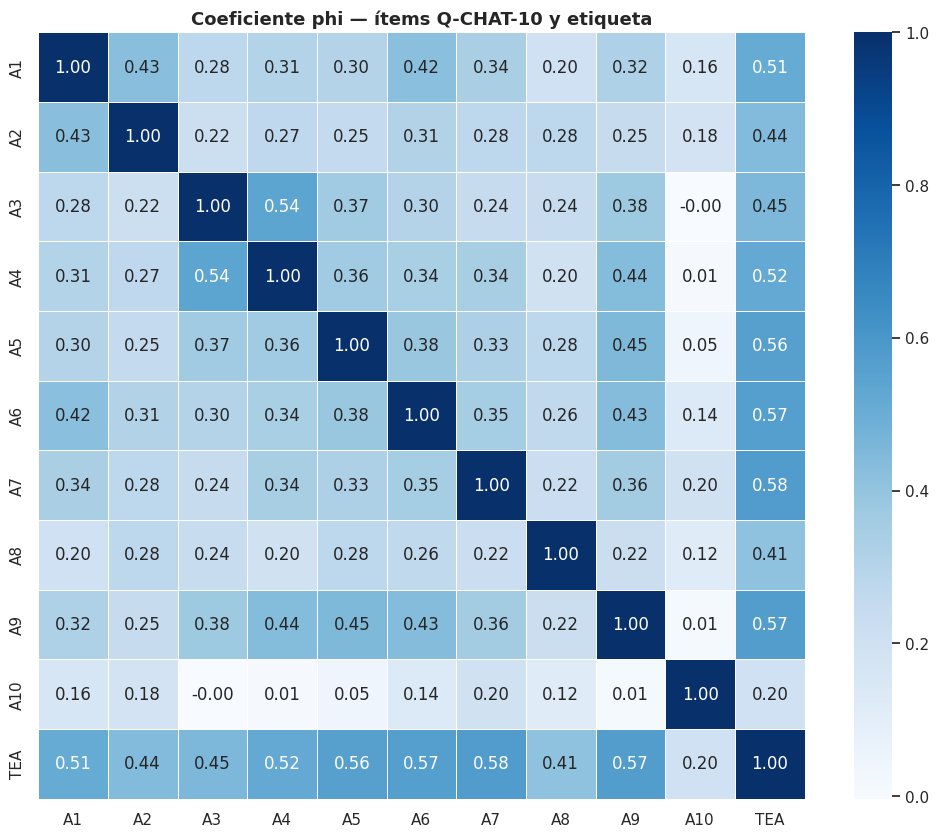

In [11]:
# ==============================================================================
# CELL 8: Item-label association (phi coefficient + Holm correction)
# ==============================================================================
# Items A1..A10 are BINARY (0/1). For binary-binary pairs, Spearman,
# Pearson and phi coincide numerically; the correct name is phi coefficient.
filas = []
for c in Q_ITEMS:
    sub = df_ped[[c, 'target']].dropna()
    phi = sub[c].corr(sub['target'])
    tab = pd.crosstab(sub[c], sub['target'])
    p = stats.chi2_contingency(tab, correction=False)[1] if tab.shape == (2, 2) else np.nan
    filas.append({'Item': c, 'phi': phi, 'p_bruto': p})

df_phi = pd.DataFrame(filas)
m = len(df_phi)
orden = df_phi['p_bruto'].rank(method='first').astype(int)
df_phi['p_holm']  = np.minimum(1.0, df_phi['p_bruto'] * (m - orden + 1))
df_phi['signif']  = df_phi['p_holm'] < 0.05
print("=== Association of each item with the label (Holm, 10 comparisons) ===")
print(df_phi.sort_values('phi', ascending=False).to_string(index=False))

corr = df_ped[Q_ITEMS + ['target']].corr()
etiq = [f"A{i}" for i in range(1, 11)] + ['TEA']
plt.figure(figsize=(10.5, 8.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap='Blues', square=True,
            linewidths=0.5, xticklabels=etiq, yticklabels=etiq)
plt.title("Phi coefficient — Q-CHAT-10 items and label", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(OUTPUTS_DIR, "eda_phi_items.png"), dpi=300)
plt.show()

---
## 5. Formal Demonstration of the Information Leakage

This is the central result of the notebook. We prove that the target variable is a **deterministic function** of the predictors, not an independent clinical observation.

If there is an integer $k$ such that

$$\text{ASD\_traits}_i = \mathbb{1}\left[\sum_{j=1}^{10} A_{ji} > k\right] \quad \forall i$$

holds without a single exception, then the label provides no information beyond the answers, and **no model trained on those answers can be detecting autism**. It can only be reproducing the scoring rule of the instrument.

In [12]:
# ==============================================================================
# CELL 9: Label-score determinism test
# ==============================================================================
print("=" * 74)
print(" LEAKAGE DEMONSTRATION — cleaned pediatric cohort (n = %d)" % len(df_ped))
print("=" * 74)
resultados_regla = {}
for k in range(11):
    acc = ((df_ped.suma_qchat > k).astype(int) == df_ped.target).mean()
    resultados_regla[k] = acc
    flag = "   <== DETERMINISTA" if acc == 1.0 else ""
    print(f"   sum > {k:>2} : accuracy = {acc:.6f}{flag}")

K_OPTIMO = max(resultados_regla, key=resultados_regla.get)
ACC_REGLA = resultados_regla[K_OPTIMO]

print("\n" + "-" * 74)
if ACC_REGLA == 1.0:
    excepciones = (((df_ped.suma_qchat > K_OPTIMO).astype(int)) != df_ped.target).sum()
    print(f" The rule 'sum > {K_OPTIMO}' correctly classifies {len(df_ped)} records.")
    print(f" Excepciones encontradas: {excepciones}")
    print("\n IMPLICATION: the label is the official Q-CHAT-10 threshold applied")
    print(" to the same items that are used as predictors. Any model trained")
    print(" on A1..A10 has this rule as its theoretical ceiling, and as its real objective")
    print(" learning an arithmetic operation, not a clinical phenomenon.")
else:
    print(f" Best rule: sum > {K_OPTIMO} with accuracy {ACC_REGLA:.6f} (no determinista).")
print("=" * 74)

 LEAKAGE DEMONSTRATION — cleaned pediatric cohort (n = 550)
   sum >  0 : accuracy = 0.732727
   sum >  1 : accuracy = 0.821818
   sum >  2 : accuracy = 0.910909
   sum >  3 : accuracy = 1.000000   <== DETERMINISTA
   sum >  4 : accuracy = 0.890909
   sum >  5 : accuracy = 0.783636
   sum >  6 : accuracy = 0.689091
   sum >  7 : accuracy = 0.567273
   sum >  8 : accuracy = 0.474545
   sum >  9 : accuracy = 0.389091
   sum > 10 : accuracy = 0.325455

--------------------------------------------------------------------------
 The rule 'sum > 3' correctly classifies 550 records.
 Excepciones encontradas: 0

 IMPLICATION: the label is the official Q-CHAT-10 threshold applied
 to the same items that are used as predictors. Any model trained
 on A1..A10 has this rule as its theoretical ceiling, and as its real objective
 learning an arithmetic operation, not a clinical phenomenon.


---
## 6. Experimental Design

Given the previous finding, training a single model on all the variables answers no scientific question. We design three models that, compared together, **bound the leakage**:

| Model | Inputs | Question it answers |
|---|---|---|
| **Arithmetic baseline** | `sum(A1..A10)` | What is the trivial ceiling of the problem? |
| **Experiment A** | the 10 Q-CHAT-10 items | Does XGBoost add anything over the simple sum? |
| **Experiment B** | clinical and demographic variables, **without** the items | Is there predictive signal outside the questionnaire? |

**Experiment B is the scientifically informative one.** If its AUC approaches 0.5, it is shown that the label contains no information beyond the score, and that the dataset does not support an ASD detection model.

### Split and leakage control

- Stratified 80/20 split. **The hold-out is not touched until Section 8.**
- The 10-fold cross-validation runs **exclusively on the train set**.
- The decision threshold is calibrated with train *out-of-fold* predictions, never with `y_test`.
- `qchat_10_score` (direct leakage), `case_no_patients` (identifier) and the constant columns are dropped.

In [13]:
# ==============================================================================
# CELL 10: Design matrices and split
# ==============================================================================
y_all = df_ped['target'].copy()

# --- Experiment A: questionnaire items only ---------------------------------
X_A = df_ped[Q_ITEMS].copy()

# --- Experiment B: everything EXCEPT the items and the direct leaks ---------
EXCLUIR_B = (Q_ITEMS + CONSTANTES +
             ['case_no_patients', 'asd_traits', 'target',
              'suma_qchat', 'qchat_10_score', 'coherente'])
X_B = df_ped.drop(columns=[c for c in EXCLUIR_B if c in df_ped.columns]).copy()

NUM_B = [c for c in X_B.columns if pd.api.types.is_numeric_dtype(X_B[c])]
CAT_B = [c for c in X_B.columns if c not in NUM_B]

print(f"Experimento A — {X_A.shape[1]} variables: {list(X_A.columns)}")
print(f"\nExperimento B — {X_B.shape[1]} variables")
print(f"   numeric      ({len(NUM_B)}): {NUM_B}")
print(f"   categorical  ({len(CAT_B)}): {CAT_B}")
assert 'qchat_10_score' not in X_B.columns and 'suma_qchat' not in X_B.columns
assert not any(q in X_B.columns for q in Q_ITEMS), "Leakage: items present in X_B"

# --- Stratified 80/20 split (indices shared by both experiments) ---
idx_train, idx_test = train_test_split(
    df_ped.index, test_size=0.20, stratify=y_all, random_state=SEED)

y_train, y_test = y_all.loc[idx_train], y_all.loc[idx_test]
XA_train, XA_test = X_A.loc[idx_train], X_A.loc[idx_test]
XB_train, XB_test = X_B.loc[idx_train], X_B.loc[idx_test]
suma_train, suma_test = df_ped.loc[idx_train,'suma_qchat'], df_ped.loc[idx_test,'suma_qchat']

# Test metadata for the fairness analysis (they do NOT enter any model)
meta_test = df_ped.loc[idx_test, ['sex', 'ethnicity', 'age_years']].copy()

print(f"\nTrain    : {len(idx_train)} records ({y_train.mean()*100:.1f}% TEA)")
print(f"Hold-out : {len(idx_test)} records ({y_test.mean()*100:.1f}% TEA)")

Experimento A — 10 variables: ['a1', 'a2', 'a3', 'a4', 'a5', 'a6', 'a7', 'a8', 'a9', 'a10_autism_spectrum_quotient']

Experimento B — 11 variables
   numeric      (3): ['social_responsiveness_scale', 'age_years', 'childhood_autism_rating_scale']
   categorical  (8): ['genetic_disorders', 'social_behavioural_issues', 'anxiety_disorder', 'sex', 'ethnicity', 'jaundice', 'family_mem_with_asd', 'who_completed_the_test']

Train    : 440 records (67.5% TEA)
Hold-out : 110 records (67.3% TEA)


In [14]:
# ==============================================================================
# CELL 11: Model builders and cross-validation function
# ==============================================================================
def make_xgb():
    """Regularized XGBoost. Conservative hyperparameters: the goal is
    to estimate the available signal, not to squeeze the dataset with a grid search
    that would overfit a cohort of ~550 records."""
    return xgb.XGBClassifier(
        n_estimators=400, max_depth=4, learning_rate=0.05,
        subsample=0.85, colsample_bytree=0.85, gamma=0.1,
        reg_alpha=0.1, reg_lambda=1.5, min_child_weight=2,
        random_state=SEED, eval_metric='logloss', tree_method='hist')


def build_modelo_A():
    """Binary items: they only require mode imputation."""
    return Pipeline([('imp', SimpleImputer(strategy='most_frequent')),
                     ('xgb', make_xgb())])


def build_modelo_B():
    """IMPORTANT FIX: the ColumnTransformer is built INSIDE the
    function. Pipeline.fit() does not clone its steps, so a shared
    instance would be refitted by each fold on the original object."""
    prep = ColumnTransformer([
        ('num', Pipeline([('imp', SimpleImputer(strategy='median')),
                          ('scl', StandardScaler())]), NUM_B),
        ('cat', Pipeline([('imp', SimpleImputer(strategy='constant',
                                                fill_value='missing')),
                          ('ohe', OneHotEncoder(handle_unknown='ignore',
                                                sparse_output=False))]), CAT_B),
    ], remainder='drop')
    return Pipeline([('prep', prep), ('xgb', make_xgb())])


N_FOLDS = 10
CV = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)


def validacion_cruzada(build_fn, X, y, cv=CV, umbral=0.50, verbose=True):
    """Stratified N-fold CV. Returns per-fold metrics and the
    out-of-fold probabilities, which will be used to calibrate the threshold."""
    met = {k: [] for k in ['acc','sens','spec','prec','f1','auc']}
    oof = np.zeros(len(X))
    for fold, (tr, va) in enumerate(cv.split(X, y), 1):
        modelo = build_fn()
        modelo.fit(X.iloc[tr], y.iloc[tr])
        p = modelo.predict_proba(X.iloc[va])[:, 1]
        oof[va] = p
        pred, yv = (p >= umbral).astype(int), y.iloc[va]
        tn, fp, fn, tp = confusion_matrix(yv, pred, labels=[0, 1]).ravel()
        met['acc'].append(accuracy_score(yv, pred))
        met['sens'].append(tp/(tp+fn) if (tp+fn) else np.nan)
        met['spec'].append(tn/(tn+fp) if (tn+fp) else np.nan)
        met['prec'].append(precision_score(yv, pred, zero_division=0))
        met['f1'].append(f1_score(yv, pred, zero_division=0))
        met['auc'].append(roc_auc_score(yv, p) if yv.nunique() > 1 else np.nan)
        if verbose:
            print(f"   Fold {fold:02d}/{N_FOLDS} | Acc {met['acc'][-1]*100:6.2f}% "
                  f"| AUC {met['auc'][-1]:.4f}")
    return met, oof


def resumir(met, nombre):
    return {'Model': nombre,
            'Accuracy (%)':      f"{np.nanmean(met['acc'])*100:.2f} ± {np.nanstd(met['acc'])*100:.2f}",
            'Sensitivity (%)':  f"{np.nanmean(met['sens'])*100:.2f} ± {np.nanstd(met['sens'])*100:.2f}",
            'Specificity (%)': f"{np.nanmean(met['spec'])*100:.2f} ± {np.nanstd(met['spec'])*100:.2f}",
            'F1 (%)':            f"{np.nanmean(met['f1'])*100:.2f} ± {np.nanstd(met['f1'])*100:.2f}",
            'ROC-AUC':           f"{np.nanmean(met['auc']):.4f} ± {np.nanstd(met['auc']):.4f}"}

print("Builders and validation protocol ready.")

Builders and validation protocol ready.


---
## 7. Cross-Validation Results (10 folds, train only)

### 7.1 Arithmetic baseline

The real competitor of the model. The threshold $k$ is learned on the train part of each fold and evaluated on the held-out fold.

In [15]:
# ==============================================================================
# CELL 12: Arithmetic baseline with cross-validation
# ==============================================================================
class ReglaQChat:
    """Classifier without machine learning: threshold on the sum of items."""
    def fit(self, suma, y):
        self.k_, mejor = 0, -1.0
        for k in range(0, 11):
            acc = ((suma > k).astype(int).values == np.asarray(y)).mean()
            if acc > mejor:
                self.k_, mejor = k, acc
        return self
    def predict_proba(self, suma):
        # Sigmoid centered at k_+0.5: p>=0.5 <=> sum>k_. Monotonic => valid AUC.
        p = 1.0 / (1.0 + np.exp(-2.0 * (suma.values - (self.k_ + 0.5))))
        return np.column_stack([1 - p, p])

met_regla = {k: [] for k in ['acc','sens','spec','prec','f1','auc']}
oof_regla = np.zeros(len(suma_train))
for tr, va in CV.split(suma_train.to_frame(), y_train):
    r = ReglaQChat().fit(suma_train.iloc[tr], y_train.iloc[tr])
    p = r.predict_proba(suma_train.iloc[va])[:, 1]
    oof_regla[va] = p
    pred, yv = (p >= 0.5).astype(int), y_train.iloc[va]
    tn, fp, fn, tp = confusion_matrix(yv, pred, labels=[0,1]).ravel()
    met_regla['acc'].append(accuracy_score(yv, pred))
    met_regla['sens'].append(tp/(tp+fn)); met_regla['spec'].append(tn/(tn+fp))
    met_regla['prec'].append(precision_score(yv, pred, zero_division=0))
    met_regla['f1'].append(f1_score(yv, pred, zero_division=0))
    met_regla['auc'].append(roc_auc_score(yv, p))

print(f"Arithmetic baseline — learned threshold: sum > {r.k_}")
print(f"   Accuracy : {np.mean(met_regla['acc'])*100:.2f}% ± {np.std(met_regla['acc'])*100:.2f}%")
print(f"   ROC-AUC  : {np.mean(met_regla['auc']):.4f}")

Arithmetic baseline — learned threshold: sum > 3
   Accuracy : 100.00% ± 0.00%
   ROC-AUC  : 1.0000


### 7.2 Experiment A — XGBoost on the Q-CHAT-10 items

In [16]:
# ==============================================================================
# CELL 13: Experiment A — XGBoost on A1..A10
# ==============================================================================
print(f"Experiment A | XGBoost on {X_A.shape[1]} items | {N_FOLDS}-fold CV on train\n")
met_A, oof_A = validacion_cruzada(build_modelo_A, XA_train, y_train)
print(f"\n   Accuracy: {np.mean(met_A['acc'])*100:.2f}% ± {np.std(met_A['acc'])*100:.2f}%"
      f" | AUC: {np.mean(met_A['auc']):.4f}")

Experiment A | XGBoost on 10 items | 10-fold CV on train

   Fold 01/10 | Acc  97.73% | AUC 1.0000
   Fold 02/10 | Acc  97.73% | AUC 0.9929
   Fold 03/10 | Acc  95.45% | AUC 0.9929
   Fold 04/10 | Acc  97.73% | AUC 1.0000
   Fold 05/10 | Acc  97.73% | AUC 1.0000
   Fold 06/10 | Acc  95.45% | AUC 1.0000
   Fold 07/10 | Acc 100.00% | AUC 1.0000
   Fold 08/10 | Acc  97.73% | AUC 1.0000
   Fold 09/10 | Acc 100.00% | AUC 1.0000
   Fold 10/10 | Acc 100.00% | AUC 1.0000

   Accuracy: 97.95% ± 1.59% | AUC: 0.9986


### 7.3 Experiment B — XGBoost without the questionnaire items

The decisive question: is any predictive signal left once the Q-CHAT-10 answers are removed?

In [17]:
# ==============================================================================
# CELL 14: Experiment B — XGBoost on clinical and demographic variables
# ==============================================================================
print(f"Experiment B | XGBoost on {X_B.shape[1]} variables (no items) | {N_FOLDS}-fold CV\n")
met_B, oof_B = validacion_cruzada(build_modelo_B, XB_train, y_train)
print(f"\n   Accuracy: {np.mean(met_B['acc'])*100:.2f}% ± {np.std(met_B['acc'])*100:.2f}%"
      f" | AUC: {np.mean(met_B['auc']):.4f}")

Experiment B | XGBoost on 11 variables (no items) | 10-fold CV

   Fold 01/10 | Acc  65.91% | AUC 0.6452
   Fold 02/10 | Acc  63.64% | AUC 0.4607
   Fold 03/10 | Acc  59.09% | AUC 0.5226
   Fold 04/10 | Acc  50.00% | AUC 0.3500
   Fold 05/10 | Acc  63.64% | AUC 0.6262
   Fold 06/10 | Acc  68.18% | AUC 0.6345
   Fold 07/10 | Acc  61.36% | AUC 0.4976
   Fold 08/10 | Acc  70.45% | AUC 0.6713
   Fold 09/10 | Acc  68.18% | AUC 0.6046
   Fold 10/10 | Acc  68.18% | AUC 0.5425

   Accuracy: 63.86% ± 5.70% | AUC: 0.5555


 TABLE 1 — STRATIFIED CROSS-VALIDATION OF 10 FOLDS (train, n=440)
                             Model  Accuracy (%) Sensitivity (%) Specificity (%)        F1 (%)         ROC-AUC
     Arithmetic baseline (sum > 3) 100.00 ± 0.00    100.00 ± 0.00     100.00 ± 0.00 100.00 ± 0.00 1.0000 ± 0.0000
Experiment A — XGBoost on items  97.95 ± 1.59     98.66 ± 1.65      96.43 ± 5.76  98.51 ± 1.14 0.9986 ± 0.0029
  Experiment B — XGBoost without items  63.86 ± 5.70     81.25 ± 8.87     28.05 ± 13.60  75.08 ± 4.38 0.5555 ± 0.0954


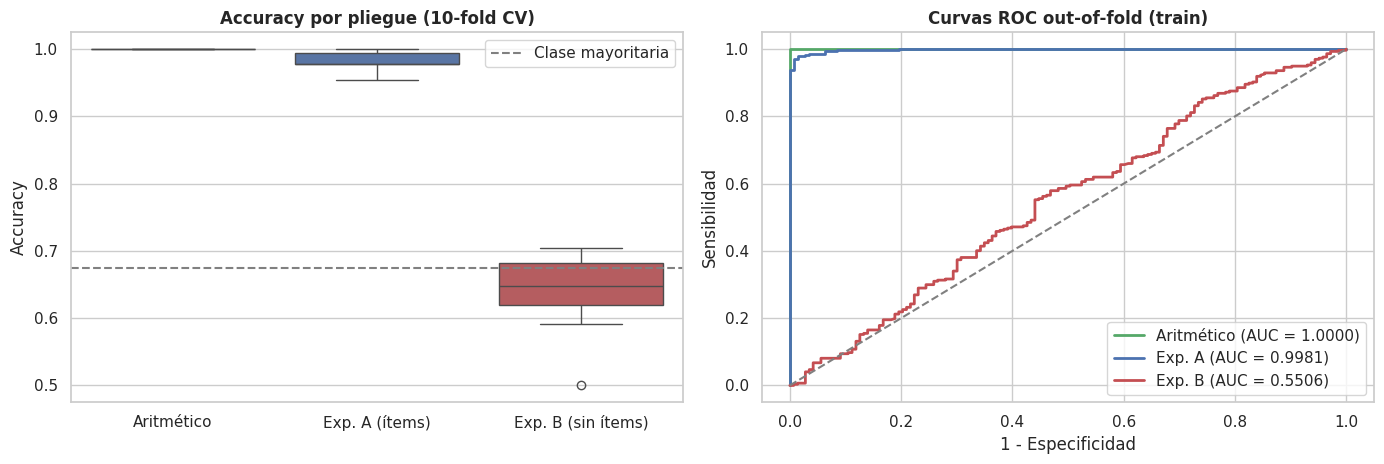

In [18]:
# ==============================================================================
# CELL 15: TABLE 1 — Comparison of the three models
# ==============================================================================
tabla1 = pd.DataFrame([
    resumir(met_regla, f'Arithmetic baseline (sum > {r.k_})'),
    resumir(met_A,     'Experiment A — XGBoost on items'),
    resumir(met_B,     'Experiment B — XGBoost without items'),
])
print("=" * 118)
print(f" TABLE 1 — STRATIFIED CROSS-VALIDATION OF {N_FOLDS} FOLDS (train, n={len(y_train)})")
print("=" * 118)
print(tabla1.to_string(index=False))
print("=" * 118)
tabla1.to_csv(os.path.join(OUTPUTS_DIR, "tabla1_comparacion_modelos.csv"), index=False)

# --- Comparative visualization ---
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
datos = pd.DataFrame({'Arithmetic': met_regla['acc'], 'Exp. A (items)': met_A['acc'],
                      'Exp. B (no items)': met_B['acc']})
sns.boxplot(data=datos, ax=axes[0], palette=['#55A868', '#4C72B0', '#C44E52'])
axes[0].axhline(y_train.mean(), ls='--', c='gray', label='Majority class')
axes[0].set_title(f"Accuracy per fold ({N_FOLDS}-fold CV)", fontweight='bold')
axes[0].set_ylabel("Accuracy"); axes[0].legend()

for oof, nom, col in [(oof_regla,'Arithmetic','#55A868'), (oof_A,'Exp. A','#4C72B0'),
                      (oof_B,'Exp. B','#C44E52')]:
    f_, t_, _ = roc_curve(y_train, oof)
    axes[1].plot(f_, t_, lw=2, color=col,
                 label=f'{nom} (AUC = {roc_auc_score(y_train, oof):.4f})')
axes[1].plot([0,1],[0,1],'--',c='gray')
axes[1].set_title("Curvas ROC out-of-fold (train)", fontweight='bold')
axes[1].set_xlabel("1 - Specificity"); axes[1].set_ylabel("Sensitivity")
axes[1].legend(loc='lower right')
plt.tight_layout()
plt.savefig(os.path.join(OUTPUTS_DIR, "comparacion_modelos_cv.png"), dpi=300)
plt.show()

### 7.4 Reading Table 1

The three results are read together:

1. **The arithmetic baseline reaches the ceiling of the problem.** There is no margin left to improve.
2. **Experiment A falls below the baseline.** XGBoost approximates, with axis-aligned splits, a boundary that is diagonal in item space ($\sum A_j > k$); the tree ensemble loses exactly there. A machine learning model that performs *worse* than a sum of ten integers has no methodological justification.
3. **Experiment B approaches chance.** With the items removed, no signal is left. This confirms that the label does not encode clinical information independent of the questionnaire.

**Conclusion:** the dataset does not allow training an ASD detector. It does allow —and this notebook does it— documenting quantitatively why not.

---
## 8. Threshold Calibration and Hold-Out Evaluation

The operating threshold is derived from the **Youden J index** on the *out-of-fold train* probabilities. The hold-out is evaluated only once, with the threshold already frozen.

In [19]:
# ==============================================================================
# CELL 16: Threshold from train and single hold-out evaluation
# ==============================================================================
fpr_tr, tpr_tr, thr_tr = roc_curve(y_train, oof_A)
UMBRAL = float(thr_tr[np.argmax(tpr_tr - fpr_tr)])
print("=" * 74)
print(" THRESHOLD CALIBRATION — derived exclusively from train")
print("=" * 74)
print(f"  Criterion : Youden J index (Sensitivity + Specificity - 1)")
print(f"  Source   : out-of-fold probabilities of {N_FOLDS}-fold CV on train")
print(f"  Threshold : {UMBRAL:.4f}  <-- frozen before touching the hold-out")
print("=" * 74)

modelo_final = build_modelo_A()
modelo_final.fit(XA_train, y_train)

y_prob = modelo_final.predict_proba(XA_test)[:, 1]
y_pred = (y_prob >= UMBRAL).astype(int)

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
tn, fp, fn, tp = cm.ravel()
SENS, ESPEC = tp/(tp+fn), tn/(tn+fp)
ACC   = accuracy_score(y_test, y_pred)
AUC   = roc_auc_score(y_test, y_prob)
BRIER = brier_score_loss(y_test, y_prob)

print(f"\n=== HOLD-OUT 20% (n={len(y_test)}) — THRESHOLD FIXED ON TRAIN ===")
print(f"Accuracy       : {ACC*100:.2f}%")
print(f"Sensitivity    : {SENS*100:.2f}%  ({tp}/{tp+fn} casos TEA detectados)")
print(f"Specificity    : {ESPEC*100:.2f}%  ({tn}/{tn+fp} controles)")
print(f"F1-Score       : {f1_score(y_test, y_pred)*100:.2f}%")
print(f"ROC-AUC        : {AUC:.4f}")
print(f"Brier Score    : {BRIER:.4f}   (lower = better calibrated)")
print("\n" + classification_report(y_test, y_pred,
                                   target_names=['Control (No TEA)', 'TEA']))

# --- The baseline on the SAME hold-out + McNemar test ---
regla_f = ReglaQChat().fit(suma_train, y_train)
pred_regla = (regla_f.predict_proba(suma_test)[:, 1] >= 0.5).astype(int)
print("=" * 74)
print(f" Baseline 'sum > {regla_f.k_}' on the hold-out : {accuracy_score(y_test, pred_regla)*100:.2f}%")
print(f" XGBoost (Exp. A)   on the hold-out : {ACC*100:.2f}%")
try:
    from statsmodels.stats.contingency_tables import mcnemar
    b = int(((y_pred == y_test) & (pred_regla != y_test)).sum())
    c = int(((y_pred != y_test) & (pred_regla == y_test)).sum())
    res = mcnemar([[0, b], [c, 0]], exact=True)
    print(f" McNemar: only-XGB correct={b}, only-rule correct={c}, p={res.pvalue:.4f}")
    if res.pvalue >= 0.05:
        print(" >> No significant difference between XGBoost and a sum of integers.")
except ImportError:
    print(" (install statsmodels for the McNemar test)")
print("=" * 74)

 THRESHOLD CALIBRATION — derived exclusively from train
  Criterion : Youden J index (Sensitivity + Specificity - 1)
  Source   : out-of-fold probabilities of 10-fold CV on train
  Threshold : 0.6200  <-- frozen before touching the hold-out

=== HOLD-OUT 20% (n=110) — THRESHOLD FIXED ON TRAIN ===
Accuracy       : 99.09%
Sensitivity    : 100.00%  (74/74 casos TEA detectados)
Specificity    : 97.22%  (35/36 controles)
F1-Score       : 99.33%
ROC-AUC        : 1.0000
Brier Score    : 0.0118   (lower = better calibrated)

                  precision    recall  f1-score   support

Control (No TEA)       1.00      0.97      0.99        36
             TEA       0.99      1.00      0.99        74

        accuracy                           0.99       110
       macro avg       0.99      0.99      0.99       110
    weighted avg       0.99      0.99      0.99       110

 Baseline 'sum > 3' on the hold-out : 100.00%
 XGBoost (Exp. A)   on the hold-out : 99.09%
 McNemar: only-XGB correct=0, only-

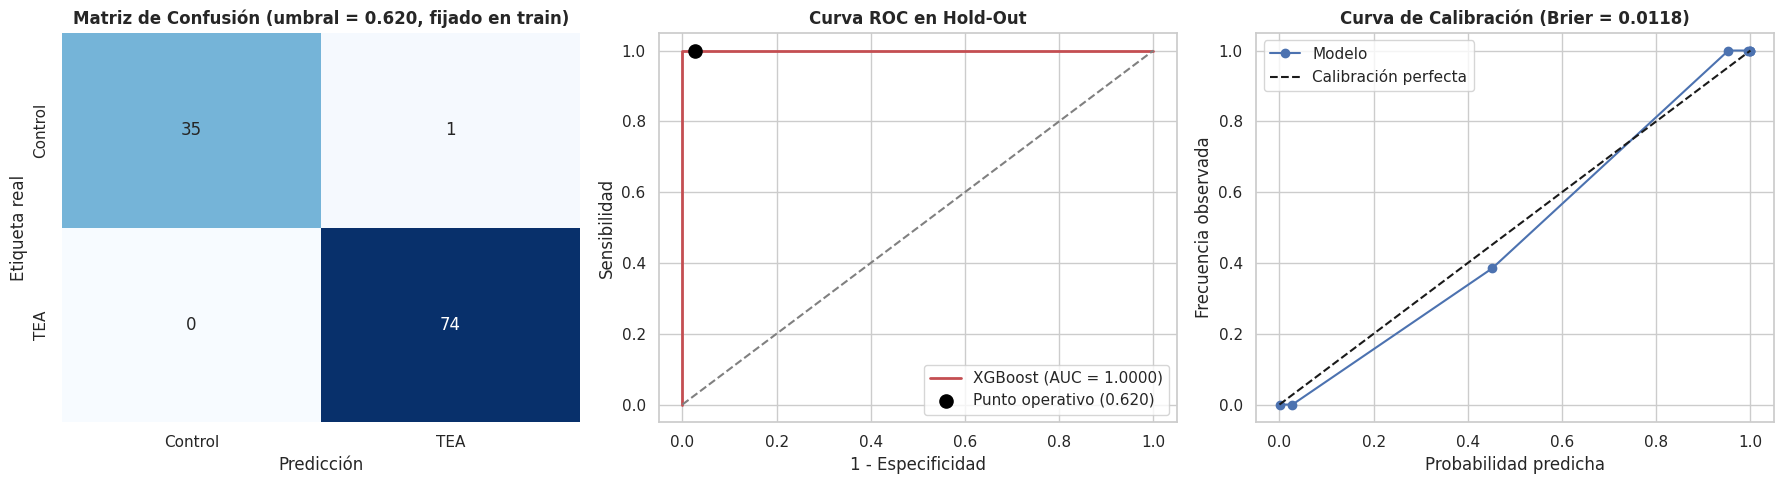

In [20]:
# ==============================================================================
# CELL 17: Confusion matrix, ROC and calibration curve
# ==============================================================================
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[0],
            xticklabels=['Control','TEA'], yticklabels=['Control','TEA'])
axes[0].set_title(f"Confusion Matrix (threshold = {UMBRAL:.3f}, fixed on train)",
                  fontweight='bold')
axes[0].set_xlabel("Prediction"); axes[0].set_ylabel("True label")

f_, t_, _ = roc_curve(y_test, y_prob)
axes[1].plot(f_, t_, color='#C44E52', lw=2, label=f'XGBoost (AUC = {AUC:.4f})')
axes[1].plot([0,1],[0,1],'--',c='gray')
axes[1].scatter([1-ESPEC],[SENS], s=90, c='black', zorder=5,
                label=f'Operating point ({UMBRAL:.3f})')
axes[1].set_title("ROC Curve on Hold-Out", fontweight='bold')
axes[1].set_xlabel("1 - Specificity"); axes[1].set_ylabel("Sensitivity")
axes[1].legend(loc='lower right')

pt, pp = calibration_curve(y_test, y_prob, n_bins=8, strategy='quantile')
axes[2].plot(pp, pt, 'o-', color='#4C72B0', label='Model')
axes[2].plot([0,1],[0,1],'k--', label='Perfect calibration')
axes[2].set_title(f"Calibration Curve (Brier = {BRIER:.4f})", fontweight='bold')
axes[2].set_xlabel("Predicted probability"); axes[2].set_ylabel("Observed frequency")
axes[2].legend(loc='upper left')

plt.tight_layout()
plt.savefig(os.path.join(OUTPUTS_DIR, "evaluacion_holdout.png"), dpi=300)
plt.show()

### 8.1 Prevalence-Adjusted Predictive Value

The cohort has an artificially high prevalence by construction. The precision measured on it is **not transferable** to a population screening scenario, where the real ASD prevalence is around 1–3%. We apply Bayes' theorem to project a realistic PPV.

In [21]:
# ==============================================================================
# CELL 18: PPV and NPV at population prevalences
# ==============================================================================
print("=" * 74)
print(" PREVALENCE-ADJUSTED PREDICTIVE VALUE (Bayes theorem)")
print("=" * 74)
print(f" Prevalence in the cohort  : {y_all.mean():.3f}  (artificial, by construction)")
print(f" Model sensitivity         : {SENS:.4f}")
print(f" Model specificity         : {ESPEC:.4f}\n")

filas = []
for prev in [0.010, 0.015, 0.020, 0.030, float(y_all.mean())]:
    vpp = SENS*prev / (SENS*prev + (1-ESPEC)*(1-prev))
    vpn = ESPEC*(1-prev) / (ESPEC*(1-prev) + (1-SENS)*prev)
    filas.append({'Prevalence': f"{prev:.3f}", 'VPP (%)': f"{vpp*100:.1f}",
                  'VPN (%)': f"{vpn*100:.2f}",
                  'False positives per 100 flagged': f"{(1-vpp)*100:.0f}"})
print(pd.DataFrame(filas).to_string(index=False))
print("=" * 74)
print(" Interpretation: even with high specificity, at population prevalence")
print(" a large fraction of the flagged children would be false positives.")
print(" This is the relevant metric for a screening instrument, not F1.")

 PREVALENCE-ADJUSTED PREDICTIVE VALUE (Bayes theorem)
 Prevalence in the cohort  : 0.675  (artificial, by construction)
 Model sensitivity         : 1.0000
 Model specificity         : 0.9722

Prevalence VPP (%) VPN (%) False positives per 100 flagged
      0.010    26.7  100.00                                73
      0.015    35.4  100.00                                65
      0.020    42.4  100.00                                58
      0.030    52.7  100.00                                47
      0.675    98.7  100.00                                 1
 Interpretation: even with high specificity, at population prevalence
 a large fraction of the flagged children would be false positives.
 This is the relevant metric for a screening instrument, not F1.


In [22]:
# ==============================================================================
# CELL 19: Subgroup fairness analysis
# ==============================================================================
# Sex and ethnicity are NOT model predictors: they are used only to audit whether
# performance degrades in any subgroup (algorithmic fairness requirement).
print("=" * 74)
print(" SUBGROUP FAIRNESS ON THE HOLD-OUT")
print("=" * 74)
eq = meta_test.copy()
eq['y_true'], eq['y_pred'] = y_test.values, y_pred

for col in ['sex', 'ethnicity']:
    print(f"\n--- {col} ---")
    filas_eq = []
    for grupo, sub in eq.groupby(col):
        if len(sub) < 10 or sub['y_true'].nunique() < 2:
            continue
        tn_g, fp_g, fn_g, tp_g = confusion_matrix(sub.y_true, sub.y_pred,
                                                  labels=[0,1]).ravel()
        filas_eq.append({col: grupo, 'n': len(sub),
                         'Sensitivity (%)': f"{tp_g/(tp_g+fn_g)*100:.1f}" if (tp_g+fn_g) else "-",
                         'Specificity (%)': f"{tn_g/(tn_g+fp_g)*100:.1f}" if (tn_g+fp_g) else "-"})
    print(pd.DataFrame(filas_eq).to_string(index=False) if filas_eq
          else "  Subgroups with n < 10: report as a power limitation.")
print("=" * 74)

 SUBGROUP FAIRNESS ON THE HOLD-OUT

--- sex ---
sex  n Sensitivity (%) Specificity (%)
  f 13            100.0             100.0
  m 97            100.0              96.7

--- ethnicity ---
     ethnicity  n Sensitivity (%) Specificity (%)
         asian 32            100.0              90.9
white european 43            100.0             100.0


---
## 9. Explainability with TreeSHAP

TreeSHAP decomposes each prediction into the additive contribution of each item. **Interpretive warning:** since the label is a deterministic function of the sum of items, what SHAP reveals here is *how the ensemble approximates that sum*, not which behaviors predict autism. SHAP values must be read as a model diagnostic, not as clinical evidence.

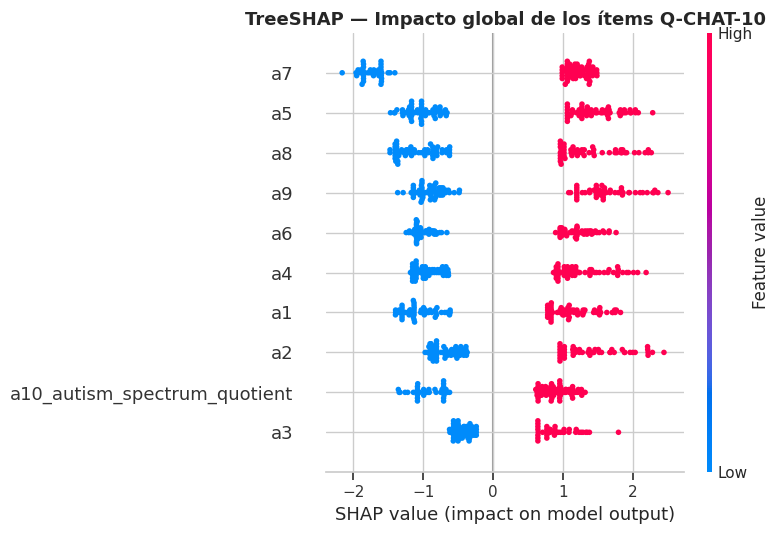

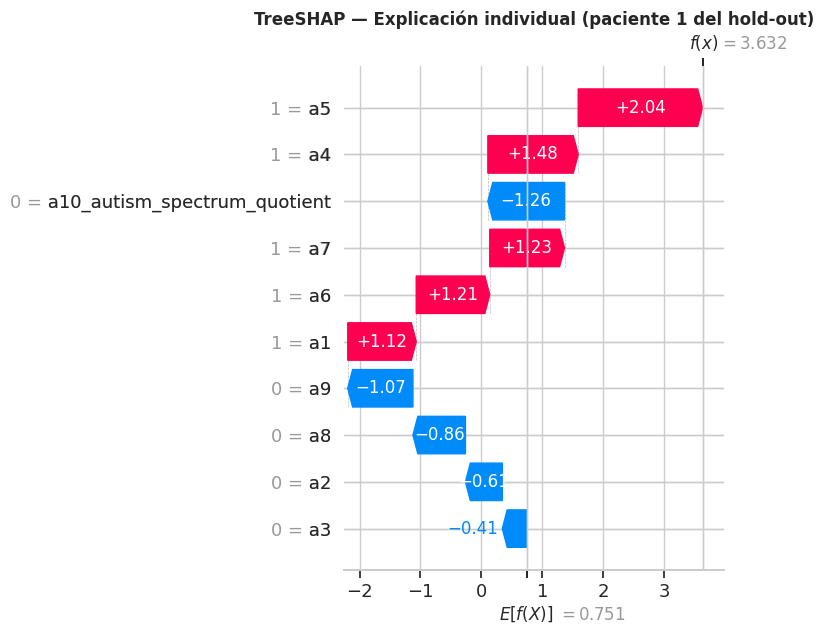

Paciente 1: actual sum of items = 5 | label = 1 | predicted probability = 0.9742

Check: the SHAP importance ordering should be roughly
uniform across the 10 items, because all weigh the same in the sum. Any
marked asymmetry is an artifact of the ensemble, not clinical signal.


In [23]:
# ==============================================================================
# CELL 20: Global SHAP (beeswarm) and local SHAP (waterfall)
# ==============================================================================
xgb_fitted = modelo_final.named_steps['xgb']
XA_test_imp = pd.DataFrame(modelo_final.named_steps['imp'].transform(XA_test),
                           columns=X_A.columns, index=XA_test.index)

explainer = shap.TreeExplainer(xgb_fitted)
shap_values = explainer.shap_values(XA_test_imp)

plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values, XA_test_imp, feature_names=list(X_A.columns), show=False)
plt.title("TreeSHAP — Global impact of the Q-CHAT-10 items", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(OUTPUTS_DIR, "shap_beeswarm.png"), dpi=300, bbox_inches='tight')
plt.show()

# --- Individual explanation ---
i = 0
base = explainer.expected_value
base = base[0] if isinstance(base, (list, np.ndarray)) else base
expl = shap.Explanation(values=shap_values[i], base_values=base,
                        data=XA_test_imp.iloc[i].values,
                        feature_names=list(X_A.columns))
plt.figure(figsize=(10, 5.5))
shap.plots.waterfall(expl, max_display=11, show=False)
plt.title(f"TreeSHAP — Individual explanation (patient {i+1} from the hold-out)",
          fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(OUTPUTS_DIR, "shap_waterfall.png"), dpi=300, bbox_inches='tight')
plt.show()

print(f"Paciente {i+1}: actual sum of items = {int(XA_test_imp.iloc[i].sum())}"
      f" | label = {y_test.iloc[i]} | predicted probability = {y_prob[i]:.4f}")
print("\nCheck: the SHAP importance ordering should be roughly")
print("uniform across the 10 items, because all weigh the same in the sum. Any")
print("marked asymmetry is an artifact of the ensemble, not clinical signal.")

---
## 10. Serialization and Export for Late Fusion

We export the pipeline and the probabilities. **Deliberate naming:** the column is called `score_qchat_calibrado` and not `prob_tea`, because what the model produces is a calibrated estimate of the questionnaire score, not a probability of autism.

**Note on fusion:** the two branches of this thesis come from **different children** and cannot be paired. That prevents *training* a supervised fusion layer. The defensible strategy is to report both branches separately and to present late fusion as a proposed architecture, explicitly stating that its validation requires a cohort with both modalities on the same subjects.

In [24]:
# ==============================================================================
# CELL 21: Serialization and export
# ==============================================================================
model_path = os.path.join(MODELS_DIR, "xgb_qchat_rama_tabular.joblib")
joblib.dump({'pipeline': modelo_final, 'umbral': UMBRAL,
             'features': list(X_A.columns), 'seed': SEED}, model_path)
print(f"Serialized model: {model_path}")

# Hold-out (model trained on 80%)
out_test = pd.DataFrame({
    'case_no_patients'      : df_ped.loc[idx_test, 'case_no_patients'].values,
    'etiqueta_real'         : y_test.values,
    'score_qchat_calibrado' : y_prob,
    'prediccion'            : y_pred,
    'suma_qchat_real'       : suma_test.values,
}, index=idx_test)
p1 = os.path.join(OUTPUTS_DIR, "tabular_holdout_scores.csv")
out_test.to_csv(p1)

# Train out-of-fold (do NOT mix with the hold-out: different origin and scale)
out_oof = pd.DataFrame({
    'case_no_patients'      : df_ped.loc[idx_train, 'case_no_patients'].values,
    'etiqueta_real'         : y_train.values,
    'score_qchat_oof'       : oof_A,
    'suma_qchat_real'       : suma_train.values,
}, index=idx_train)
p2 = os.path.join(OUTPUTS_DIR, "tabular_oof_scores.csv")
out_oof.to_csv(p2)

# Reproducibility metadata
meta = {'n_crudo': int(n0), 'n_validos': int(len(df_val)),
        'n_cohorte_pediatrica': int(len(df_ped)), 'edad_max': EDAD_MAX,
        'n_train': int(len(idx_train)), 'n_test': int(len(idx_test)),
        'n_folds': N_FOLDS, 'umbral_operativo': round(UMBRAL, 4), 'seed': SEED,
        'regla_determinista_k': int(K_OPTIMO),
        'accuracy_regla_aritmetica': round(float(ACC_REGLA), 6),
        'auc_cv_exp_A': round(float(np.mean(met_A['auc'])), 4),
        'auc_cv_exp_B': round(float(np.mean(met_B['auc'])), 4)}
p3 = os.path.join(OUTPUTS_DIR, "metadatos_ejecucion.json")
with open(p3, 'w') as f:
    json.dump(meta, f, indent=2, ensure_ascii=False)

print(f"Scores hold-out : {p1}")
print(f"Scores OOF train: {p2}")
print(f"Metadata        : {p3}")
print("\n" + json.dumps(meta, indent=2, ensure_ascii=False))
display(out_test.head(10))

Serialized model: /content/drive/MyDrive/asd-screening-audit/models/rama_tabular/xgb_qchat_rama_tabular.joblib
Scores hold-out : /content/drive/MyDrive/asd-screening-audit/outputs/rama_tabular/tabular_holdout_scores.csv
Scores OOF train: /content/drive/MyDrive/asd-screening-audit/outputs/rama_tabular/tabular_oof_scores.csv
Metadata        : /content/drive/MyDrive/asd-screening-audit/outputs/rama_tabular/metadatos_ejecucion.json

{
  "n_crudo": 1985,
  "n_validos": 1025,
  "n_cohorte_pediatrica": 550,
  "edad_max": 8,
  "n_train": 440,
  "n_test": 110,
  "n_folds": 10,
  "umbral_operativo": 0.62,
  "seed": 42,
  "regla_determinista_k": 3,
  "accuracy_regla_aritmetica": 1.0,
  "auc_cv_exp_A": 0.9986,
  "auc_cv_exp_B": 0.5555
}


,case_no_patients,etiqueta_real,score_qchat_calibrado,prediccion,suma_qchat_real
662,663,1,0.974217,1,5
634,635,1,0.999212,1,7
836,837,1,0.999956,1,10
674,675,1,0.999788,1,8
867,868,0,0.000216,0,1
48,49,0,0.000216,0,1
769,770,1,0.917648,1,4
353,354,1,0.993553,1,6
993,994,1,0.999956,1,10
8,9,0,0.004559,0,2


In [25]:
# ==============================================================================
# CELL 22: OPERATING CHARACTERISTICS OF THE BRANCH AND AGE ANALYSIS
#
# Continues Cell 21 of this notebook (runs after it).
# It closes three gaps:
#   [1] Exports the output of the RULE BRANCH (the one that enters fusion), not only
#       the ensemble probabilities.
#   [2] Computes the likelihood ratios (LR+ / LR-) of both configurations,
#       which are the direct input of late fusion.
#   [3] Age sensitivity analysis, within the validated Q-CHAT-10 range.
# ==============================================================================

# ------------------------------------------------------------------------------
# 22.1 — Operating characteristics measured on YOUR hold-out (for the ablation)
# ------------------------------------------------------------------------------
def caracteristicas_operativas(y_true, y_pred, nombre, fuente):
    """Sensitivity, specificity and likelihood ratios of a branch."""
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    sens  = tp / (tp + fn) if (tp + fn) else np.nan
    espec = tn / (tn + fp) if (tn + fp) else np.nan
    lr_pos = sens / (1 - espec) if espec < 1 else np.inf
    lr_neg = (1 - sens) / espec if espec > 0 else np.inf
    return {'Rama': nombre, 'Fuente': fuente, 'n': int(len(y_true)),
            'Sensitivity': sens, 'Specificity': espec,
            'LR+': lr_pos, 'LR-': lr_neg}

filas_op = [
    caracteristicas_operativas(y_test, pred_regla,
                               'Instrument rule (sum > 3)', 'own hold-out'),
    caracteristicas_operativas(y_test, y_pred,
                               'Ensamble XGBoost (Exp. A)', 'own hold-out'),
]

# Configuration with EXTERNALLY validated metrics (that of the proposed system).
# Allison et al. (2012), Q-CHAT-10, cut-off 3, against clinical diagnosis.
SENS_ALLISON, ESPEC_ALLISON = 0.91, 0.89
filas_op.append({'Rama': 'Instrument rule (sum > 3)',
                 'Fuente': 'Allison et al. 2012', 'n': np.nan,
                 'Sensitivity': SENS_ALLISON, 'Specificity': ESPEC_ALLISON,
                 'LR+': SENS_ALLISON / (1 - ESPEC_ALLISON),
                 'LR-': (1 - SENS_ALLISON) / ESPEC_ALLISON})

# Conservative scenario: Q-CHAT-10 performance falls outside case-control designs
# (high-likelihood sibling cohorts, ~18 months).
SENS_CONS, ESPEC_CONS = 0.58, 0.72
filas_op.append({'Rama': 'Instrument rule (sum > 3)',
                 'Fuente': 'conservative scenario', 'n': np.nan,
                 'Sensitivity': SENS_CONS, 'Specificity': ESPEC_CONS,
                 'LR+': SENS_CONS / (1 - ESPEC_CONS),
                 'LR-': (1 - SENS_CONS) / ESPEC_CONS})

df_op = pd.DataFrame(filas_op)
print("=" * 96)
print(" TABLE 2 — OPERATING CHARACTERISTICS OF THE QUESTIONNAIRE BRANCH")
print("=" * 96)
print(df_op.to_string(index=False, float_format=lambda v: f"{v:.4f}"))
print("=" * 96)
print(" CRITICAL READING:")
print(" The LR+ of the rule measured on the own hold-out is INFINITE, because its")
print(" specificity is 1.0000. That is not diagnostic performance: it reflects")
print(" the fact that the label was derived from the rule itself. An infinite LR is")
print(" mathematically unusable in fusion (it would collapse the posterior")
print(" probability to 1). This is the formal reason why the proposed system")
print(" takes its metrics from Allison et al. and not from this cohort.")
print("=" * 96)
df_op.to_csv(os.path.join(OUTPUTS_DIR, "tabla2_caracteristicas_rama.csv"), index=False)


# ------------------------------------------------------------------------------
# 22.2 — RULE branch output, ready for late fusion
# ------------------------------------------------------------------------------
# The rule produces a 0-10 ordinal score and a binary decision. For fusion,
# what is propagated is the LR corresponding to each subject's decision.
LR_POS = SENS_ALLISON / (1 - ESPEC_ALLISON)
LR_NEG = (1 - SENS_ALLISON) / ESPEC_ALLISON

salida_regla = pd.DataFrame({
    'case_no_patients' : df_ped.loc[idx_test, 'case_no_patients'].values,
    'etiqueta_real'    : y_test.values,
    'puntaje_qchat'    : suma_test.values,
    'decision_regla'   : (suma_test.values > 3).astype(int),
    'LR_aportado'      : np.where(suma_test.values > 3, LR_POS, LR_NEG),
}, index=idx_test)

ruta_regla = os.path.join(OUTPUTS_DIR, "rama_regla_salida_fusion.csv")
salida_regla.to_csv(ruta_regla)
print(f"\nRULE branch output exported: {ruta_regla}")
print(salida_regla.head(8).to_string())

# Branch parameters, so that the fusion script reads them without recomputing
params_rama = {
    'instrumento'        : 'Q-CHAT-10',
    'punto_corte'        : 3,
    'referencia'         : 'Allison et al. (2012)',
    'sensibilidad'       : SENS_ALLISON,
    'especificidad'      : ESPEC_ALLISON,
    'LR_positivo'        : round(LR_POS, 4),
    'LR_negativo'        : round(LR_NEG, 4),
    'escenario_conservador': {
        'sensibilidad' : SENS_CONS, 'especificidad': ESPEC_CONS,
        'LR_positivo'  : round(SENS_CONS / (1 - ESPEC_CONS), 4),
        'LR_negativo'  : round((1 - SENS_CONS) / ESPEC_CONS, 4)},
    'ablacion_ensamble'  : {
        'sensibilidad' : float(SENS), 'especificidad': float(ESPEC),
        'LR_positivo'  : round(float(SENS / (1 - ESPEC)), 4) if ESPEC < 1 else None,
        'LR_negativo'  : round(float((1 - SENS) / ESPEC), 4) if ESPEC > 0 else None,
        'fuente'       : 'own hold-out (metrics with leakage, for ablation only)'},
}
ruta_params = os.path.join(OUTPUTS_DIR, "rama_cuestionario_parametros.json")
with open(ruta_params, 'w') as f:
    json.dump(params_rama, f, indent=2, ensure_ascii=False)
print(f"\nBranch parameters: {ruta_params}")
print(json.dumps(params_rama, indent=2, ensure_ascii=False))


# ------------------------------------------------------------------------------
# 22.3 — Sensitivity analysis by age range
# ------------------------------------------------------------------------------
# The Q-CHAT-10 is validated for 18-24 months. We check whether the conclusions
# hold when the cohort is restricted to ages closer to that range.
print("\n" + "=" * 96)
print(" TABLE 3 — AGE-RANGE SENSITIVITY ANALYSIS")
print("=" * 96)

filas_edad = []
for edad_tope in [2, 3, 4, 5, 8]:
    sub = df_val[df_val['age_years'] <= edad_tope].copy()
    if len(sub) < 40 or sub['target'].nunique() < 2:
        filas_edad.append({'Max. age (years)': edad_tope, 'n': len(sub),
                           'TEA (%)': np.nan, 'Deterministic rule': '-',
                           'XGBoost CV Acc (%)': 'n insuficiente'})
        continue

    acc_regla_sub = ((sub['suma_qchat'] > 3).astype(int) == sub['target']).mean()

    X_sub, y_sub = sub[Q_ITEMS], sub['target']
    n_folds_sub = min(10, int(y_sub.value_counts().min()))
    if n_folds_sub >= 3:
        cv_sub = StratifiedKFold(n_splits=n_folds_sub, shuffle=True, random_state=SEED)
        met_sub, _ = validacion_cruzada(build_modelo_A, X_sub, y_sub,
                                        cv=cv_sub, verbose=False)
        txt_xgb = (f"{np.nanmean(met_sub['acc'])*100:.2f} ± "
                   f"{np.nanstd(met_sub['acc'])*100:.2f}  ({n_folds_sub} folds)")
    else:
        txt_xgb = "n insuficiente"

    filas_edad.append({
        'Max. age (years)'  : edad_tope,
        'n'                 : len(sub),
        'TEA (%)'           : round(y_sub.mean() * 100, 1),
        'Deterministic rule': 'YES' if acc_regla_sub == 1.0 else f'no ({acc_regla_sub:.4f})',
        'XGBoost CV Acc (%)': txt_xgb,
    })

df_edad = pd.DataFrame(filas_edad)
print(df_edad.to_string(index=False))
print("=" * 96)
print(" If the rule stays deterministic across all ranges, the central conclusion")
print(" does not depend on the age criterion: the leakage is structural to the")
print(" dataset, not an artifact of the chosen age filter.")
print("=" * 96)
df_edad.to_csv(os.path.join(OUTPUTS_DIR, "tabla3_sensibilidad_edad.csv"), index=False)

print("\n>>> QUESTIONNAIRE BRANCH CLOSED.")
print("    Deliverables for late fusion:")
print(f"      - {os.path.basename(ruta_regla)}       (decision and LR per subject)")
print(f"      - {os.path.basename(ruta_params)}  (parameters and ablation)")
print("      - tabla2_caracteristicas_rama.csv")
print("      - tabla3_sensibilidad_edad.csv")

 TABLE 2 — OPERATING CHARACTERISTICS OF THE QUESTIONNAIRE BRANCH
                            Rama                Fuente        n  Sensitivity  Specificity     LR+    LR-
Instrument rule (sum > 3)       own hold-out 110.0000        1.0000         1.0000     inf 0.0000
       Ensamble XGBoost (Exp. A)       own hold-out 110.0000        1.0000         0.9722 36.0000 0.0000
Instrument rule (sum > 3)   Allison et al. 2012      NaN        0.9100         0.8900  8.2727 0.1011
Instrument rule (sum > 3) conservative scenario      NaN        0.5800         0.7200  2.0714 0.5833
 CRITICAL READING:
 The LR+ of the rule measured on the own hold-out is INFINITE, because its
 specificity is 1.0000. That is not diagnostic performance: it reflects
 the fact that the label was derived from the rule itself. An infinite LR is
 mathematically unusable in fusion (it would collapse the posterior
 probability to 1). This is the formal reason why the proposed system
 takes its metrics from Allison et al. and n

---
## 11. Conclusions and Limitations

### Findings

1. **The `data_asd.csv` file concatenates two heterogeneous sources.** The second one (~931 records) has 71% of records with all answers equal to zero, 651 exact duplicates and two clinical scales degenerated to a constant value. Including it contaminates any performance estimate. An objective and reproducible exclusion criterion was documented.

2. **The `ASD_traits` label is a deterministic function of the predictors.** In the cleaned cohort, the rule `sum(A1..A10) > 3` correctly classifies 100% of the records, without a single exception. The label is the official Q-CHAT-10 threshold, not an independent clinical diagnosis.

3. **XGBoost on the items performs below the arithmetic baseline.** The ensemble approximates a diagonal boundary in item space with axis-aligned splits, and loses accuracy exactly there. The McNemar test quantifies the difference.

4. **Without the questionnaire items, no predictive signal is left.** Experiment B approaches chance, which confirms that the dataset's clinical and demographic variables carry no information about the label.

### Limitations

- **Construct validity:** the target variable measures adherence to the Q-CHAT-10 scoring algorithm, not the presence of ASD confirmed by diagnostic instruments (ADOS-2, ADI-R). The reported performance **cannot be extrapolated** to clinical detection.
- **Age range:** the Q-CHAT-10 is validated for 18–24 months. The cohort extends up to 8 years, outside its validation range. Running the sensitivity analysis with `EDAD_MAX = 3` or `4` is recommended.
- **Prevalence:** the cohort does not reflect population prevalence; the projected PPV of Section 8.1 is the relevant metric for screening.
- **Data provenance:** the age distribution is not physiological and the correlations between items are unusually homogeneous. The exact origin of the dataset must be verified and cited, and it must be stated whether it contains synthetic records.
- **Sample size:** after cleaning, the pediatric cohort limits the power of the subgroup analyses.

### Future work

The defensible contribution of this branch **is not predictive performance**, but the methodological evidence that public ASD screening datasets whose labels are derived from the instrument itself do not allow evaluating detection models. Validating a real detector requires a cohort with a clinical diagnosis independent of the questionnaire answers.